In [2]:

import platform
import sys

print("Python version:", sys.version)
print("Processor:", platform.machine())

try:
    import torch
    print("PyTorch version:", torch.__version__)
    print("MPS available:", torch.backends.mps.is_available())
    print("CUDA available:", torch.cuda.is_available())
except ImportError:
    print("PyTorch is not installed.")


Python version: 3.14.8 (tags/v3.14.8:8e6e75d, Sep 30 2026, 18:19:33) [MSC v.1944 64 bit (AMD64)]
Processor: AMD64
PyTorch version: 2.14.1+cu126
MPS available: False
CUDA available: True


In [3]:

import sys

print("Python executable:", sys.executable)
print("Python version:", sys.version)


Python executable: C:\Users\user\AppData\Local\Programs\Python\Python314\python.exe
Python version: 3.14.8 (tags/v3.14.8:8e6e75d, Sep 30 2026, 18:19:33) [MSC v.1944 64 bit (AMD64)]


In [4]:

import sys
import torch
import torchvision

print("Python:", sys.version)
print("Python environment:", sys.executable)
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("MPS available:", torch.backends.mps.is_available())


Python: 3.14.8 (tags/v3.14.8:8e6e75d, Sep 30 2026, 18:19:33) [MSC v.1944 64 bit (AMD64)]
Python environment: C:\Users\user\AppData\Local\Programs\Python\Python314\python.exe
PyTorch: 2.14.1+cu126
Torchvision: 0.29.1+cu126
MPS available: False



# IAI600 - CIFAR-10 Image Classification Project

## 1. Dataset Loading and Exploration

This project compares Multilayer Perceptron (MLP) and
Convolutional Neural Network (CNN) architectures
for image classification using the CIFAR-10 dataset.


In [ ]:

import torch
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np

from torchvision.datasets import CIFAR10

# Use Apple GPU if available
device = torch.device(
    "mps" if torch.backends.mps.is_available() else "cpu"
)

print("Device:", device)

# Convert images into PyTorch tensors
transform = transforms.ToTensor()

# Download training dataset
train_dataset = CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

# Download test dataset
test_dataset = CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

# CIFAR-10 classes
classes = train_dataset.classes

print("Training images:", len(train_dataset))
print("Test images:", len(test_dataset))
print("Image shape:", train_dataset[0][0].shape)
print("Classes:", classes)


Device: cpu


37.2%


## 1.2 Dataset Visualization

In this section, we visualize sample images from
the CIFAR-10 dataset to understand its structure,
image characteristics, and class labels.


In [1]:

import matplotlib.pyplot as plt
import numpy as np

# CIFAR-10 class names
classes = train_dataset.classes

# Display one example from each class
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for class_idx in range(10):

    # Find the first image belonging to this class
    image_idx = train_dataset.targets.index(class_idx)

    # Get image and label
    image, label = train_dataset[image_idx]

    # Convert from [C, H, W] to [H, W, C]
    image = image.permute(1, 2, 0).numpy()

    # Display image
    ax = axes[class_idx // 5, class_idx % 5]
    ax.imshow(image)
    ax.set_title(classes[label])
    ax.axis("off")

plt.suptitle("CIFAR-10 Sample Images", fontsize=14)
plt.tight_layout()
plt.show()


ModuleNotFoundError: No module named 'matplotlib'


## 1.3 Class Distribution Analysis

This section examines the number of images in each
CIFAR-10 class to determine whether the dataset
is balanced across all categories.


Class Distribution:
---------------------------------------------
airplane     | Train:  5000 | Test:  1000
automobile   | Train:  5000 | Test:  1000
bird         | Train:  5000 | Test:  1000
cat          | Train:  5000 | Test:  1000
deer         | Train:  5000 | Test:  1000
dog          | Train:  5000 | Test:  1000
frog         | Train:  5000 | Test:  1000
horse        | Train:  5000 | Test:  1000
ship         | Train:  5000 | Test:  1000
truck        | Train:  5000 | Test:  1000


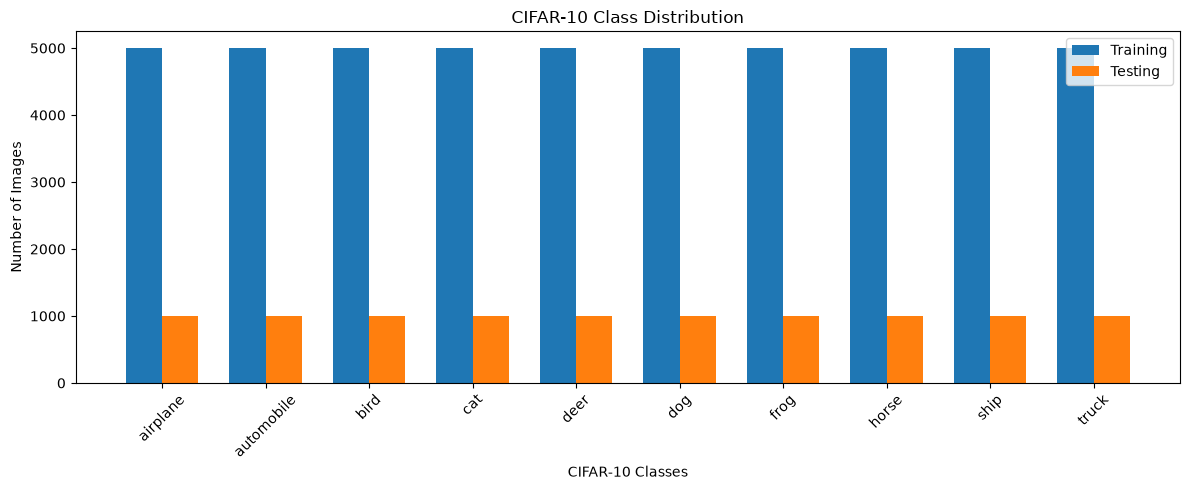

In [4]:

import numpy as np
import matplotlib.pyplot as plt

# Count images for each class
train_counts = np.bincount(
    train_dataset.targets, minlength=10
)

test_counts = np.bincount(
    test_dataset.targets, minlength=10
)

# Display the number of images
print("Class Distribution:")
print("-" * 45)

for i, class_name in enumerate(classes):
    print(
        f"{class_name:12s} | "
        f"Train: {train_counts[i]:5d} | "
        f"Test: {test_counts[i]:5d}"
    )

# Create bar chart
x = np.arange(len(classes))
width = 0.35

plt.figure(figsize=(12, 5))

plt.bar(
    x - width/2,
    train_counts,
    width,
    label="Training"
)

plt.bar(
    x + width/2,
    test_counts,
    width,
    label="Testing"
)

plt.xlabel("CIFAR-10 Classes")
plt.ylabel("Number of Images")
plt.title("CIFAR-10 Class Distribution")
plt.xticks(x, classes, rotation=45)
plt.legend()
plt.tight_layout()
plt.show()



## 1.4 Stratified Train/Validation Split

The original CIFAR-10 training dataset contains
50,000 images.

We split this dataset into 90% training and
10% validation data using stratified sampling.

Stratification preserves the class distribution,
ensuring that all 10 classes are equally represented.

A fixed random seed (42) is used for reproducibility.
The original test set remains unchanged.


In [5]:

from sklearn.model_selection import train_test_split
from torch.utils.data import Subset
import numpy as np

# Original labels from CIFAR-10 training dataset
labels = np.array(train_dataset.targets)

# Indices for all 50,000 training images
indices = np.arange(len(train_dataset))

# Stratified split: 90% training, 10% validation
train_indices, val_indices = train_test_split(
    indices,
    test_size=0.10,
    random_state=42,
    stratify=labels
)

# Create training and validation subsets
train_subset = Subset(train_dataset, train_indices)
val_subset = Subset(train_dataset, val_indices)

# Verify dataset sizes
print("Training samples:", len(train_subset))
print("Validation samples:", len(val_subset))
print("Test samples:", len(test_dataset))

# Verify class distribution
train_labels = labels[train_indices]
val_labels = labels[val_indices]

print("\nClass Distribution After Split:")
print("-" * 45)

for i, class_name in enumerate(classes):
    train_count = np.sum(train_labels == i)
    val_count = np.sum(val_labels == i)

    print(
        f"{class_name:12s} | "
        f"Train: {train_count:5d} | "
        f"Validation: {val_count:4d}"
    )


Training samples: 45000
Validation samples: 5000
Test samples: 10000

Class Distribution After Split:
---------------------------------------------
airplane     | Train:  4500 | Validation:  500
automobile   | Train:  4500 | Validation:  500
bird         | Train:  4500 | Validation:  500
cat          | Train:  4500 | Validation:  500
deer         | Train:  4500 | Validation:  500
dog          | Train:  4500 | Validation:  500
frog         | Train:  4500 | Validation:  500
horse        | Train:  4500 | Validation:  500
ship         | Train:  4500 | Validation:  500
truck        | Train:  4500 | Validation:  500



## 1.5 Data Normalization

We compute channel-wise mean and standard deviation
using only the training subset.

The same normalization parameters will be applied
to training, validation, and test images to avoid
data leakage and ensure consistent preprocessing.


In [6]:

from torch.utils.data import DataLoader

# Temporary DataLoader for computing statistics
stats_loader = DataLoader(
    train_subset,
    batch_size=256,
    shuffle=False,
    num_workers=0
)

channel_sum = torch.zeros(3)
channel_sum_sq = torch.zeros(3)
total_pixels = 0

for images, labels_batch in stats_loader:
    channel_sum += images.sum(dim=(0, 2, 3))
    channel_sum_sq += (images ** 2).sum(dim=(0, 2, 3))
    total_pixels += images.shape[0] * images.shape[2] * images.shape[3]

mean = channel_sum / total_pixels
std = torch.sqrt(
    channel_sum_sq / total_pixels - mean ** 2
)

print("Training mean:", mean)
print("Training std:", std)


Training mean: tensor([0.4911, 0.4821, 0.4464])
Training std: tensor([0.2469, 0.2434, 0.2616])


In [7]:

from torchvision import transforms
from torchvision.datasets import CIFAR10
from torch.utils.data import Subset

# Normalization transform
normalized_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=mean.tolist(),
        std=std.tolist()
    )
])

# Load the existing datasets with normalization
normalized_train_full = CIFAR10(
    root="./data",
    train=True,
    download=False,
    transform=normalized_transform
)

normalized_test = CIFAR10(
    root="./data",
    train=False,
    download=False,
    transform=normalized_transform
)

# Reuse exactly the same indices
train_final = Subset(normalized_train_full, train_indices)
val_final = Subset(normalized_train_full, val_indices)
test_final = normalized_test

print("Training:", len(train_final))
print("Validation:", len(val_final))
print("Testing:", len(test_final))


Training: 45000
Validation: 5000
Testing: 10000


In [8]:

from torch.utils.data import DataLoader

BATCH_SIZE = 64

train_loader = DataLoader(
    train_final,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_final,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_final,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

# Verify one batch
images, labels = next(iter(train_loader))

print("Batch images shape:", images.shape)
print("Batch labels shape:", labels.shape)
print("Image dtype:", images.dtype)


Batch images shape: torch.Size([64, 3, 32, 32])
Batch labels shape: torch.Size([64])
Image dtype: torch.float32



## 1.6 Final Preprocessing Verification

This section verifies that the normalized training
dataset has approximately zero channel-wise mean
and unit standard deviation.

It also verifies that the training, validation,
and test datasets contain the expected samples.


In [9]:

# Verify normalization using the complete training set
channel_sum = torch.zeros(3)
channel_sum_sq = torch.zeros(3)
total_pixels = 0

for images_batch, _ in train_loader:
    channel_sum += images_batch.sum(dim=(0, 2, 3))
    channel_sum_sq += (images_batch ** 2).sum(dim=(0, 2, 3))
    total_pixels += images_batch.shape[0] * 32 * 32

verified_mean = channel_sum / total_pixels
verified_std = torch.sqrt(
    channel_sum_sq / total_pixels - verified_mean ** 2
)

print("Normalized training mean:", verified_mean)
print("Normalized training std:", verified_std)

print("\nDataset sizes:")
print("Training:", len(train_final))
print("Validation:", len(val_final))
print("Test:", len(test_final))

# Final checks
assert len(train_final) == 45000
assert len(val_final) == 5000
assert len(test_final) == 10000

assert set(train_indices).isdisjoint(set(val_indices))

assert torch.allclose(
    verified_mean, torch.zeros(3), atol=1e-4
)

assert torch.allclose(
    verified_std, torch.ones(3), atol=1e-4
)

print("\nAll preprocessing checks passed!")


Normalized training mean: tensor([ 1.4268e-07,  5.4614e-07, -4.9724e-08])
Normalized training std: tensor([1.0000, 1.0000, 1.0000])

Dataset sizes:
Training: 45000
Validation: 5000
Test: 10000

All preprocessing checks passed!



## 1.7 Reproducibility and Group Handoff

We save the exact training and validation indices
and normalization parameters to ensure that the
MLP and CNN models use identical data partitions
and preprocessing settings.


In [10]:

import json
from pathlib import Path

# Create a folder for shared configuration files
config_dir = Path("config")
config_dir.mkdir(exist_ok=True)

# Save exact dataset indices
np.savez(
    config_dir / "split_indices.npz",
    train_indices=train_indices,
    val_indices=val_indices
)

# Save preprocessing parameters
config = {
    "dataset": "CIFAR-10",
    "random_state": 42,
    "training_samples": 45000,
    "validation_samples": 5000,
    "test_samples": 10000,
    "batch_size": BATCH_SIZE,
    "mean": mean.tolist(),
    "std": std.tolist(),
    "classes": classes
}

with open(
    config_dir / "preprocessing_config.json",
    "w"
) as file:
    json.dump(config, file, indent=4)

print("Configuration files saved successfully!")
print("Files:")
print(config_dir / "split_indices.npz")
print(config_dir / "preprocessing_config.json")


Configuration files saved successfully!
Files:
config/split_indices.npz
config/preprocessing_config.json



## 1.8 Configuration Verification

This section verifies that the saved preprocessing
configuration and dataset indices can be reloaded
correctly for reproducible experiments.


In [11]:

import json
import numpy as np

# Load saved dataset indices
saved_indices = np.load("config/split_indices.npz")

saved_train = saved_indices["train_indices"]
saved_val = saved_indices["val_indices"]

# Load saved preprocessing configuration
with open("config/preprocessing_config.json", "r") as file:
    saved_config = json.load(file)

# Verify saved values
assert np.array_equal(saved_train, train_indices)
assert np.array_equal(saved_val, val_indices)

assert len(saved_train) == 45000
assert len(saved_val) == 5000

assert np.allclose(saved_config["mean"], mean.numpy())
assert np.allclose(saved_config["std"], std.numpy())

print("Training indices:", len(saved_train))
print("Validation indices:", len(saved_val))
print("Saved mean:", saved_config["mean"])
print("Saved std:", saved_config["std"])
print("Batch size:", saved_config["batch_size"])

print("\nAll configuration checks passed!")


Training indices: 45000
Validation indices: 5000
Saved mean: [0.4911373257637024, 0.4821110665798187, 0.44644901156425476]
Saved std: [0.246869295835495, 0.24343018233776093, 0.261603444814682]
Batch size: 64

All configuration checks passed!


In [12]:

from data_preparation import get_cifar10_loaders

# Load datasets using the shared module
train_loader_shared, val_loader_shared, test_loader_shared = (
    get_cifar10_loaders()
)

# Check dataset sizes
print("Training:", len(train_loader_shared.dataset))
print("Validation:", len(val_loader_shared.dataset))
print("Testing:", len(test_loader_shared.dataset))

# Check one batch
images, labels = next(iter(train_loader_shared))

print("\nBatch image shape:", images.shape)
print("Batch label shape:", labels.shape)

print("\nShared data preparation module works!")


Training: 45000
Validation: 5000
Testing: 10000

Batch image shape: torch.Size([64, 3, 32, 32])
Batch label shape: torch.Size([64])

Shared data preparation module works!
